In [1]:
pip install scikit-learn streamlit

Note: you may need to restart the kernel to use updated packages.


c:\Users\parth.DESKTOP-5935\Desktop\Work\Pandas\Battery_Claude_V2\.venv\Scripts\python.exe: No module named pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

In [4]:
df = pd.read_csv("../src/final_data.csv")
df.head()

,battery_id,cycle,capacity,voltage_mean,voltage_min,voltage_max,voltage_std,current_mean,current_min,current_max,...,voltage_slope,ic_peak_height,ic_peak_voltage,SOH,EOL_cycle,RUL,censored,cycle_normalized,voltage_range,temperature_range
0,B0005,1,1.856487,3.529829,2.612467,4.191492,0.236558,-1.818702,-2.018015,0.000729,...,-0.000206,6.351944,3.479329,100.000000,162.0,161.0,False,0.005952,1.579024,14.656188
1,B0005,2,1.846327,3.537320,2.587209,4.189773,0.235366,-1.817560,-2.016821,0.002927,...,-0.000205,6.781573,3.500066,99.452721,162.0,160.0,False,0.011905,1.602564,14.347450
2,B0005,3,1.835349,3.543737,2.651917,4.188187,0.228111,-1.816487,-2.016574,0.001484,...,-0.000200,6.854167,3.482607,98.861386,162.0,159.0,False,0.017857,1.536270,14.084531
3,B0005,4,1.835263,3.543666,2.592948,4.188461,0.233347,-1.825589,-2.015936,0.001547,...,-0.000205,6.988207,3.496433,98.856718,162.0,158.0,False,0.023810,1.595513,14.110061
4,B0005,5,1.834646,3.542343,2.547420,4.188299,0.237301,-1.826114,-2.017426,0.001701,...,-0.000208,6.098681,3.510383,98.823482,162.0,157.0,False,0.029762,1.640879,14.146692


In [5]:
"""train = df[df['battery_id'].isin(['B0005', 'B0006', 'B0018'])]

test = df[
    df['battery_id'].isin(['B0007'])
]"""

features = [
    'cycle',
    'cycle_normalized',
    'voltage_mean',
    'voltage_min',
    'voltage_max',
    'voltage_std',
    'voltage_range',
    'current_mean',
    'current_min',
    'current_max',
    'current_std',
    'temperature_mean',
    'temperature_min',
    'temperature_max',
    'temperature_std',
    'temperature_range',
    'current_load_mean',
    'voltage_load_mean',
    'duration'
]

batteries = ['B0005', 'B0006', 'B0007', 'B0018']

results = []

for b in batteries:
    print(f"\n ======= Test Battery: {b} ======")

    train = df[df['battery_id'] != b]
    test = df[df['battery_id'] == b]

    X_train = train[features]
    y_train = train['SOH']

    X_test = test[features]
    y_test = test['SOH']

    models = {
        'Linear Regression': LinearRegression(),

        'Decision Tree': DecisionTreeRegressor(max_depth=5, min_samples_leaf=3, random_state=42),

        'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),

        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
    }

    for model_name, model in models.items():

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        mse = mean_squared_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)

        results.append({
            'Test Battery': b,
            'Model': model_name,
            'MSE': mse,
            'R2': r2
        })

        print(
            f"{model_name}: "
            f"MSE = {mse:.6f}, "
            f"R² = {r2:.6f}"
        )

results_df = pd.DataFrame(results)

print("\n================ Results for Each Battery ================\n")
print(results_df)


# Calculate average performance for each model
average_results = (
    results_df
    .groupby('Model')[['MSE', 'R2']]
    .mean()
    .reset_index()
)

print("\n================ Average Performance ================\n")
print(average_results)

"""linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)

bagging_model = RandomForestRegressor(n_estimators=10, random_state=42)
bagging_model.fit(X_train, y_train)
bagging_predictions = bagging_model.predict(X_test)

boosting_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
boosting_model.fit(X_train, y_train)
boosting_predictions = boosting_model.predict(X_test)

def evaluate_model(predictions, y_test, model_name):
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    print(f"{model_name} - Mean Squared Error: {mse}, R-squared: {r2}")

print("===============================   SOH prediction for various models   ==============================")
evaluate_model(linear_predictions, y_test, 'Linear Regression')
evaluate_model(dt_predictions, y_test, 'Decision Tree Regressor')
evaluate_model(boosting_predictions, y_test, 'Gradient Boosting Regressor')
evaluate_model(bagging_predictions, y_test, 'Random Forest Regressor') 79 86 69 84 (DT, GB, LR, RF)"""


 ======= Test Battery: B0005 ======
Linear Regression: MSE = 17.543932, R² = 0.832231
Decision Tree: MSE = 12.173766, R² = 0.883585
Random Forest: MSE = 4.582231, R² = 0.956181
Gradient Boosting: MSE = 3.358393, R² = 0.967884

 ======= Test Battery: B0006 ======
Linear Regression: MSE = 43.340001, R² = 0.715670
Decision Tree: MSE = 73.922760, R² = 0.515033
Random Forest: MSE = 65.542658, R² = 0.570011
Gradient Boosting: MSE = 60.567222, R² = 0.602652

 ======= Test Battery: B0007 ======
Linear Regression: MSE = 7.936910, R² = 0.889778
Decision Tree: MSE = 3.863910, R² = 0.946341
Random Forest: MSE = 3.189610, R² = 0.955705
Gradient Boosting: MSE = 3.552318, R² = 0.950668

 ======= Test Battery: B0018 ======
Linear Regression: MSE = 27.567994, R² = 0.601543
Decision Tree: MSE = 9.367034, R² = 0.864613
Random Forest: MSE = 5.823073, R² = 0.915836
Gradient Boosting: MSE = 3.908738, R² = 0.943505

================ Results for Each Battery ================

   Test Battery              Mod

'linear_model = LinearRegression()\nlinear_model.fit(X_train, y_train)\nlinear_predictions = linear_model.predict(X_test)\n\ndt_model = DecisionTreeRegressor(random_state=42)\ndt_model.fit(X_train, y_train)\ndt_predictions = dt_model.predict(X_test)\n\nbagging_model = RandomForestRegressor(n_estimators=10, random_state=42)\nbagging_model.fit(X_train, y_train)\nbagging_predictions = bagging_model.predict(X_test)\n\nboosting_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)\nboosting_model.fit(X_train, y_train)\nboosting_predictions = boosting_model.predict(X_test)\n\ndef evaluate_model(predictions, y_test, model_name):\n    mse = mean_squared_error(y_test, predictions)\n    r2 = r2_score(y_test, predictions)\n    print(f"{model_name} - Mean Squared Error: {mse}, R-squared: {r2}")\n\nprint("===============================   SOH prediction for various models   ==============================")\nevaluate_model(linear_predictions, y_test, \'Linear Regres

## RUL modeling

In [6]:
# ============================================================
# RUL (Remaining Useful Life) modeling
# ------------------------------------------------------------
# RUL only has ground truth for batteries that actually crossed the 70%
# SOH threshold during testing (see the 'censored' flag from
# feature_engineering.ipynb). A censored battery has NaN RUL for every
# single one of its rows, so it can't be used for training OR evaluation
# here - there's nothing to check predictions against. We exclude it from
# this section entirely (it's still fine to use for the SOH model above).
# ============================================================

rul_df = df.dropna(subset=['RUL']).copy()
rul_batteries = sorted(rul_df['battery_id'].unique())
excluded = sorted(set(df['battery_id'].unique()) - set(rul_batteries))

print(f"Batteries usable for RUL modeling: {rul_batteries}")
print(f"Batteries excluded (censored, no ground-truth RUL): {excluded}")

rul_results = []

for b in rul_batteries:
    print(f"\n ======= RUL Test Battery: {b} ======")

    train = rul_df[rul_df['battery_id'] != b]
    test = rul_df[rul_df['battery_id'] == b]

    X_train, y_train = train[features], train['RUL']
    X_test, y_test = test[features], test['RUL']

    rul_models = {
        'Linear Regression': LinearRegression(),
        'Decision Tree': DecisionTreeRegressor(max_depth=5, min_samples_leaf=3, random_state=42),
        'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
    }

    for model_name, model in rul_models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        mse = mean_squared_error(y_test, predictions)
        mae = mean_absolute_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)

        rul_results.append({'Test Battery': b, 'Model': model_name, 'MSE': mse, 'MAE': mae, 'R2': r2})
        print(f"{model_name}: MSE = {mse:.2f}, MAE = {mae:.2f}, R\u00b2 = {r2:.4f}")

rul_results_df = pd.DataFrame(rul_results)
print("\n================ RUL Results for Each Battery ================\n")
print(rul_results_df)

rul_average_results = rul_results_df.groupby('Model')[['MSE', 'MAE', 'R2']].mean().reset_index()
print("\n================ RUL Average Performance ================\n")
print(rul_average_results)

Batteries usable for RUL modeling: ['B0005', 'B0006']
Batteries excluded (censored, no ground-truth RUL): ['B0007', 'B0018']

 ======= RUL Test Battery: B0005 ======
Linear Regression: MSE = 3600.00, MAE = 60.00, R² = -0.5307
Decision Tree: MSE = 3204.10, MAE = 56.24, R² = -0.3623
Random Forest: MSE = 3240.04, MAE = 56.74, R² = -0.3776
Gradient Boosting: MSE = 3338.80, MAE = 57.65, R² = -0.4196

 ======= RUL Test Battery: B0006 ======
Linear Regression: MSE = 3600.00, MAE = 60.00, R² = -0.5307
Decision Tree: MSE = 3198.28, MAE = 56.24, R² = -0.3599
Random Forest: MSE = 3107.64, MAE = 55.56, R² = -0.3213
Gradient Boosting: MSE = 3307.48, MAE = 57.43, R² = -0.4063

================ RUL Results for Each Battery ================

  Test Battery              Model          MSE        MAE        R2
0        B0005  Linear Regression  3600.000000  60.000000 -0.530666
1        B0005      Decision Tree  3204.102679  56.241071 -0.362337
2        B0005      Random Forest  3240.039285  56.738869 -0

## Investigating the B0006 generalization gap

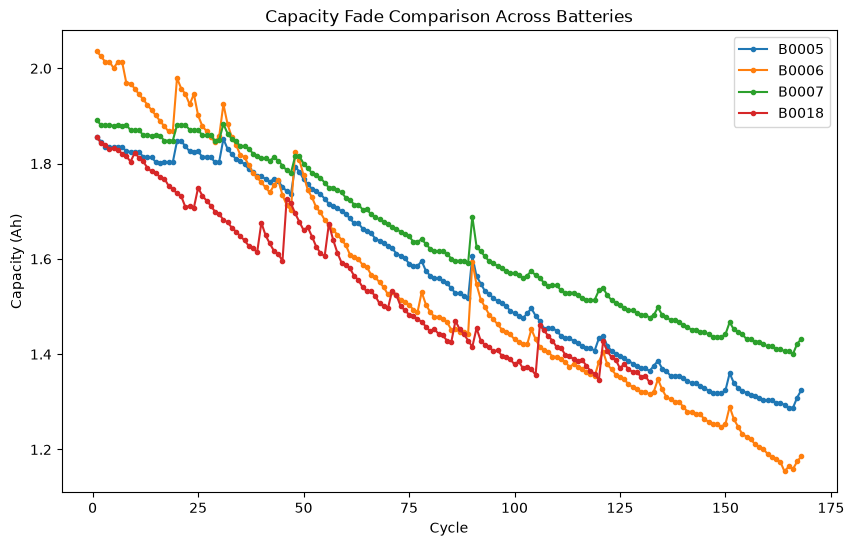

            first_capacity  last_capacity  n_cycles  fade_rate_per_cycle
battery_id                                                              
B0005             1.856487       1.325079     168.0             0.003163
B0006             2.035338       1.185675     168.0             0.005058
B0007             1.891052       1.432455     168.0             0.002730
B0018             1.855005       1.341051     132.0             0.003894


In [7]:
# ============================================================
# Why does B0006 generalize worse than the other batteries?
# (R\u00b2 dropped to ~0.5-0.7 for B0006 vs ~0.83-0.96 for B0005/B0007/B0018
# in the SOH results above, across every model - that's not noise.)
# ============================================================

plt.figure(figsize=(10, 6))
for b in df['battery_id'].unique():
    sub = df[df['battery_id'] == b].sort_values('cycle')
    plt.plot(sub['cycle'], sub['capacity'], marker='o', markersize=3, label=b)

plt.xlabel('Cycle')
plt.ylabel('Capacity (Ah)')
plt.title('Capacity Fade Comparison Across Batteries')
plt.legend()
plt.show()

fade_summary = df.groupby('battery_id').apply(lambda g: pd.Series({
    'first_capacity': g.sort_values('cycle')['capacity'].iloc[0],
    'last_capacity': g.sort_values('cycle')['capacity'].iloc[-1],
    'n_cycles': g['cycle'].max(),
    'fade_rate_per_cycle': (g.sort_values('cycle')['capacity'].iloc[0] - g.sort_values('cycle')['capacity'].iloc[-1]) / g['cycle'].max()
}))
print(fade_summary)

## Saving models for deployment

In [8]:
# ============================================================
# Save trained models for deployment (needed for Step 6 - the closed-loop
# predictive control service that consumes MQTT and needs to load a
# trained model without retraining every time it starts).
#
# For deployment we train on ALL available data - the leave-one-battery-out
# loop above is for honestly measuring generalization, not for producing
# the model you actually ship.
# ============================================================

import joblib
import os

os.makedirs('../models', exist_ok=True)

final_soh_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
final_soh_model.fit(df[features], df['SOH'])
joblib.dump(final_soh_model, '../models/soh_model.pkl')

if len(rul_batteries) > 0:
    final_rul_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
    final_rul_model.fit(rul_df[features], rul_df['RUL'])
    joblib.dump(final_rul_model, '../models/rul_model.pkl')

joblib.dump(features, '../models/feature_list.pkl')
print("Saved soh_model.pkl, rul_model.pkl, feature_list.pkl to ../models/")

Saved soh_model.pkl, rul_model.pkl, feature_list.pkl to ../models/


## Feature importance (SHAP)

In [9]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


c:\Users\parth.DESKTOP-5935\Desktop\Work\Pandas\Battery_Claude_V2\.venv\Scripts\python.exe: No module named pip


c:\Users\parth.DESKTOP-5935\Desktop\Work\Pandas\Battery_Claude_V2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


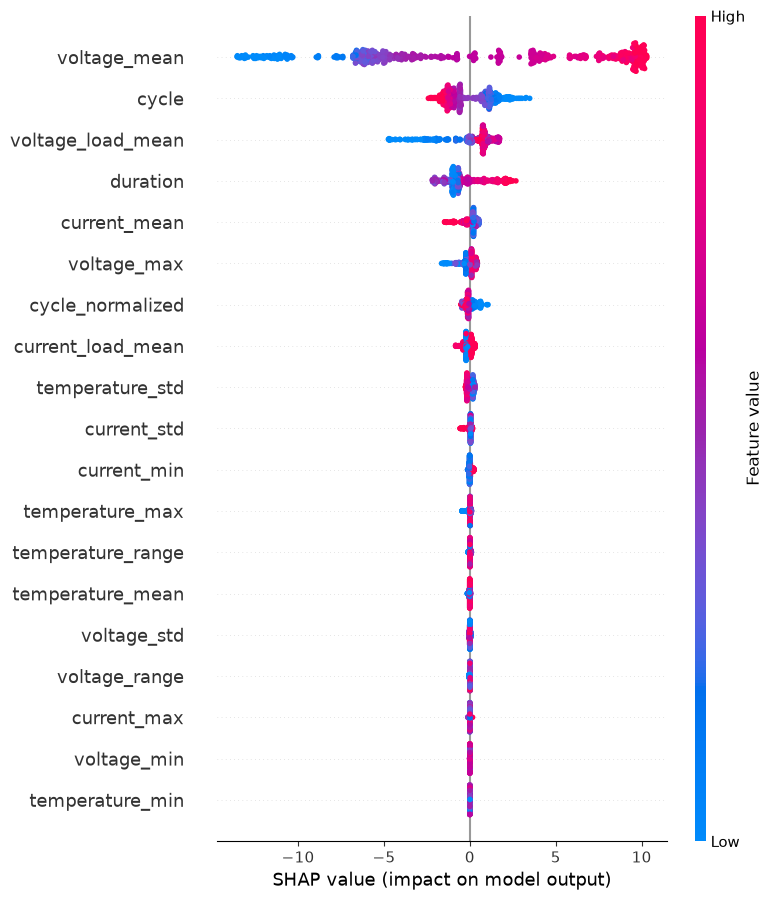

In [10]:
# ============================================================
# SHAP feature importance - which sensor signals actually drive the
# prediction? Useful for (a) the report/patent's explainability angle,
# and (b) sanity-checking the Step 6 degradation-acceleration rule
# against features you can actually threshold on the ESP32.
# ============================================================

import shap

explainer = shap.TreeExplainer(final_soh_model)
shap_values = explainer.shap_values(df[features])
shap.summary_plot(shap_values, df[features], show=True)